# Notebook 10: Grad-CAM for all four models, with baselines and ViT attention rollout (reviewer item 2.2)

For the E1 recipe-F models of **all five folds** and all four fine-tuned architectures, this notebook measures how much of the Grad-CAM attention falls on the weapon mask of each test image, and compares it with two chance baselines:
- **shifted mask**: the same mask moved by half the image in both directions (wrap-around), so the area is equal but the position is wrong;
- **other-image mask**: the mask of a different, randomly paired test image.

For ViT-S/16 it also computes **attention rollout** (Abnar and Zuidema, 2020), a second explanation method that does not use gradients, so the low weapon share of the ViT can be checked with an independent method. No training is done.

**Inputs (Add Input -> Your Work):** Stage 0 output, Notebook 1 output (`bg_removed/mask_manifest.csv`, the weapon masks), Notebook 2 output, final version (`results/all`).
Settings: GPU T4 x1, Internet not needed. Time: about 15 to 25 min for five folds (set `FOLDS = [0]` for about 5 min).

**Outputs (`/kaggle/working/gradcam_all_models/`):** `cam_per_image.csv`, `cam_summary_by_fold.csv`, `cam_summary.csv` (mean and SD over folds: the new Table 5), `cam_per_class.csv`, `gradcam_all_models.pdf/.png` (figure), and a zip.

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
import os, json, math, time, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score
import torch, torch.nn.functional as F_, timm
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path(os.environ.get("BD_INPUT", "/kaggle/input" if ON_KAGGLE else r"H:\BD Weapon Inputs"))
WORK = Path(os.environ.get("BD_WORK", "/kaggle/working" if ON_KAGGLE else r"H:\BD Weapon Analysis"))
MODELS_ALL = ["resnet50", "efficientnet_b0", "convnext_tiny", "vit_small_patch16_224"]
NAME = {"resnet50": "ResNet-50", "efficientnet_b0": "EfficientNet-B0", "convnext_tiny": "ConvNeXt-Tiny",
        "vit_small_patch16_224": "ViT-S/16"}
SEED, PAD_GRAY = 42, 128
print("device:", DEVICE, "| timm", timm.__version__, "| torch", torch.__version__)

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
    return None

STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
RES = walk_find(INPUT_ROOT, lambda d, f: d if ("summary_all.csv" in f and d.name == "all"
                                              and d.parent.name == "results") else None)
assert STAGE0, "Stage 0 output not found (Add Input -> Your Work -> Stage 0 notebook)."
print("Stage 0   :", STAGE0); print("Notebook 2:", RES)

manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
CLASS_MAP = json.loads((STAGE0 / "metadata" / "class_map.json").read_text())
CLASSES = sorted(CLASS_MAP, key=CLASS_MAP.get)
manifest["y"] = manifest.label.map(CLASS_MAP)
test = manifest[manifest.split == "test"].reset_index(drop=True)
print(f"{len(manifest)} images, {len(test)} test images, classes: {CLASSES}")

def letterbox(img, res, pad):                    # identical to Notebook 2
    h, w = img.shape[:2]; s = res / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    out = np.full((res, res) + img.shape[2:], pad, img.dtype)
    t, l = (res - nh) // 2, (res - nw) // 2
    out[t:t + nh, l:l + nw] = small
    return out

def geometric(img, cfg, pad):
    if cfg["size"] == "stretch":
        return cv2.resize(img, (cfg["res"], cfg["res"]), interpolation=cv2.INTER_AREA)
    return letterbox(img, cfg["res"], pad)

def clahe_rgb(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def convert_color(rgb, color):
    if color == "gray":
        return np.repeat(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[..., None], 3, axis=2)
    if color == "hsv":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL)
    if color == "lab":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    return rgb

summ = pd.read_csv(RES / "summary_all.csv").drop_duplicates(["model", "pipeline"], keep="last") if RES else None

def cfg_of(model, pipe="F"):
    s = summ[(summ.model == model) & (summ.pipeline == pipe)].iloc[0]
    return {"bg": s.cfg_bg, "size": s.cfg_size, "res": int(s.cfg_res), "color": s.cfg_color}

def folds_of(model, pipe="F"):
    return sorted(int(p.stem[4:]) for p in (RES / model / pipe / "weights").glob("fold*.pt"))

def load_net(model, fold, pipe="F"):
    cfg = cfg_of(model, pipe)
    kw = dict(pretrained=False, num_classes=len(CLASSES))
    if model.startswith("vit"):
        kw["img_size"] = cfg["res"]
    net = timm.create_model(model, **kw)
    sd = torch.load(RES / model / pipe / "weights" / f"fold{fold}.pt", map_location="cpu")
    net.load_state_dict({k: v.float() for k, v in sd.items()})
    nj = RES / model / pipe / "weights" / "norm.json"
    if nj.exists():
        n = json.loads(nj.read_text())[str(fold)]; mean, std = n["mean"], n["std"]
    else:
        mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    mean = torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1)
    std = torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1)
    return net.eval().to(DEVICE), cfg, mean, std

def to_tensor(batch_uint8, color, mean, std):
    x = np.stack([convert_color(im, color) for im in batch_uint8])
    x = torch.from_numpy(x).permute(0, 3, 1, 2).float() / 255
    return (x - mean) / std

device: cuda | timm 1.0.30 | torch 2.11.0+cu130
Stage 0   : /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0
Notebook 2: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/all
2950 images, 419 test images, classes: ['Churi', 'Dao', 'Khor', 'Kodal', 'Kural', 'Shabol']


In [2]:
FOLDS = [0, 1, 2, 3, 4]          # [0] for a quick run
MODELS = MODELS_ALL
DEBUG_N = None
OUT = WORK / "gradcam_all_models"; OUT.mkdir(parents=True, exist_ok=True)

BGR = walk_find(INPUT_ROOT, lambda d, f: d if ("mask_manifest.csv" in f and d.name == "bg_removed") else None)
assert BGR, "Notebook 1 output not found (Add Input -> Your Work -> background-removal notebook)."
mm = pd.read_csv(BGR / "mask_manifest.csv", dtype={"image_id": str})
tst = test.merge(mm[["image_id", "mask_path", "mask_status"]], on="image_id", how="left")
tst = tst[tst.mask_status == "ok"].reset_index(drop=True)
if DEBUG_N:
    tst = tst.groupby("label", group_keys=False).head(max(1, DEBUG_N // len(CLASSES))).reset_index(drop=True)
cfg0 = cfg_of(MODELS[0])
IMGS, MASKS = [], []
for r in tst.itertuples(index=False):
    rgb = np.asarray(Image.open(STAGE0 / r.path).convert("RGB"))
    if cfg0["color"] == "clahe":
        rgb = clahe_rgb(rgb)
    IMGS.append(geometric(rgb, cfg0, PAD_GRAY))
    m = np.asarray(Image.open(BGR / r.mask_path).convert("L")).astype(np.float32) / 255
    MASKS.append(geometric(m, cfg0, 0.0))
IMGS, MASKS = np.stack(IMGS), np.stack(MASKS)
H = IMGS.shape[1]
SHIFTED = np.roll(MASKS, (H // 2, H // 2), axis=(1, 2))
perm = np.random.default_rng(SEED).permutation(len(tst))
while np.any(perm == np.arange(len(tst))):                  # every image gets another image's mask
    perm = np.random.default_rng(int(perm[0]) + 1).permutation(len(tst))
OTHER = MASKS[perm]
print(f"{len(tst)} test images with a mask | input {H} px | mean weapon area {MASKS.mean():.3f}")

406 test images with a mask | input 384 px | mean weapon area 0.088


In [3]:
def target_layer(net, model):              # identical to Notebook 3
    if model.startswith("resnet"):
        return net.layer4
    if model.startswith("convnext"):
        return net.stages[-1]
    if model.startswith("efficientnet"):
        return net.bn2
    if model.startswith("vit"):
        return net.blocks[-1].norm1
    raise ValueError(model)

class GradCAM:                               # identical to Notebook 3 (predicted class, ReLU, bilinear, max-normalized)
    def __init__(self, net, model):
        self.net, self.prefix = net, getattr(net, "num_prefix_tokens", 1)
        self.h = target_layer(net, model).register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.act = o
        o.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x):
        self.net.zero_grad()
        with torch.enable_grad():
            logits = self.net(x)
            cls = int(logits.argmax(1)); logits[0, cls].backward()
        a, g = self.act.detach(), self.grad.detach()
        if a.dim() == 3:                     # ViT tokens -> grid, class token removed
            a, g = a[:, self.prefix:], g[:, self.prefix:]
            n = int(round(math.sqrt(a.shape[1])))
            a = a.reshape(1, n, n, -1).permute(0, 3, 1, 2); g = g.reshape(1, n, n, -1).permute(0, 3, 1, 2)
        cam = torch.relu((g.mean((2, 3), keepdim=True) * a).sum(1))[0].float().cpu().numpy()
        cam = cv2.resize(cam, (x.shape[3], x.shape[2]), interpolation=cv2.INTER_LINEAR)
        cam = cam / cam.max() if cam.max() > 0 else cam
        return cam, cls, torch.softmax(logits.detach(), 1)[0, cls].item()

class Rollout:                               # attention rollout (Abnar and Zuidema 2020), mean over heads
    def __init__(self, net):
        self.net, self.att, self.prefix = net, [], getattr(net, "num_prefix_tokens", 1)
        for b in net.blocks:
            if hasattr(b.attn, "fused_attn"):
                b.attn.fused_attn = False    # explicit softmax so the attention matrix can be read
            b.attn.attn_drop.register_forward_hook(lambda m, i, o: self.att.append(o.detach()))
    def map(self, size):
        if not self.att:
            return None
        n_tok = self.att[0].shape[-1]; R = torch.eye(n_tok, device=self.att[0].device)
        for A in self.att:
            A = A[0].float().mean(0) + torch.eye(n_tok, device=A.device)
            R = (A / A.sum(-1, keepdim=True)) @ R
        v = R[0, self.prefix:]; n = int(round(math.sqrt(v.numel())))
        m = v.reshape(n, n).cpu().numpy()
        m = cv2.resize(m, (size, size), interpolation=cv2.INTER_LINEAR)
        m = m - m.min()
        return m / m.max() if m.max() > 0 else m

share = lambda cam, mask: float((cam * mask).sum() / max(cam.sum(), 1e-8))

In [4]:
rows, KEEP = [], {}
pick = [int(tst.index[tst.label == c][0]) for c in CLASSES if (tst.label == c).any()]   # figure: first image per class
for m in MODELS:
    for k in [f for f in FOLDS if f in folds_of(m)]:
        t0 = time.time()
        net, cfg, mean, std = load_net(m, k)
        cam_fn = GradCAM(net, m)
        roll = Rollout(net) if m.startswith("vit") else None
        for i, r in enumerate(tst.itertuples(index=False)):
            x = to_tensor(IMGS[i:i + 1], cfg["color"], mean, std).to(DEVICE)
            if roll: roll.att.clear()
            cam, cls, conf = cam_fn(x)
            area = float(MASKS[i].mean()); s = share(cam, MASKS[i])
            row = {"model": m, "fold": k, "image_id": r.image_id, "label": r.label, "subset": r.subset,
                   "correct": cls == r.y, "confidence": conf, "weapon_area": area,
                   "cam_on_weapon": s, "rho": s / max(area, 1e-6),
                   "cam_on_shifted": share(cam, SHIFTED[i]), "cam_on_other": share(cam, OTHER[i]),
                   "other_area": float(OTHER[i].mean())}
            if roll:
                rm = roll.map(H)
                if rm is not None:
                    row.update(rollout_on_weapon=share(rm, MASKS[i]), rollout_on_shifted=share(rm, SHIFTED[i]))
                    if k == FOLDS[0] and i in pick: KEEP[("rollout", i)] = rm
            if k == FOLDS[0] and i in pick:
                KEEP[(m, i)] = (cam, CLASSES[cls], conf)
            rows.append(row)
        cam_fn.h.remove(); del net, cam_fn, roll
        torch.cuda.empty_cache() if DEVICE == "cuda" else None
        d = pd.DataFrame(rows); d = d[(d.model == m) & (d.fold == k)]
        print(f"{NAME[m]:16s} fold {k}: on weapon {d.cam_on_weapon.mean():.3f} | shifted {d.cam_on_shifted.mean():.3f} | "
              f"other {d.cam_on_other.mean():.3f} | median rho {d.rho.median():.2f}"
              + (f" | rollout {d.rollout_on_weapon.mean():.3f}" if "rollout_on_weapon" in d else "")
              + f" | {time.time() - t0:.0f} s")

cam = pd.DataFrame(rows); cam.to_csv(OUT / "cam_per_image.csv", index=False)
agg = dict(images=("image_id", "nunique"), weapon_area=("weapon_area", "mean"), on_weapon=("cam_on_weapon", "mean"),
           on_shifted=("cam_on_shifted", "mean"), on_other=("cam_on_other", "mean"), rho_median=("rho", "median"),
           accuracy=("correct", "mean"))
if "rollout_on_weapon" in cam:
    agg.update(rollout_on_weapon=("rollout_on_weapon", "mean"), rollout_on_shifted=("rollout_on_shifted", "mean"))
by_fold = cam.groupby(["model", "fold"]).agg(**agg).reset_index()
by_fold["above_shifted"] = by_fold.on_weapon / by_fold.on_shifted
by_fold.round(4).to_csv(OUT / "cam_share_by_fold.csv", index=False)
summary = by_fold.drop(columns=["fold"]).groupby("model", sort=False).agg(["mean", "std"]).round(3)
summary.to_csv(OUT / "cam_summary.csv"); display(summary)
# per image: is the weapon share higher than the shifted-mask share? (pooled over folds)
win = cam.assign(w=cam.cam_on_weapon > cam.cam_on_shifted).groupby("model").w.mean().round(3)
print("share of images with more attention on the weapon than on the shifted mask:"); print(win.to_string())
win.to_csv(OUT / "cam_beats_shifted.csv")
cam.pivot_table(index=["model", "label"], values=["cam_on_weapon", "cam_on_shifted", "rho"],
                aggfunc={"cam_on_weapon": "mean", "cam_on_shifted": "mean", "rho": "median"}
                ).round(3).to_csv(OUT / "cam_per_class.csv")
cam.pivot_table(index=["model", "subset"], values=["cam_on_weapon", "cam_on_shifted"], aggfunc="mean"
                ).round(3).to_csv(OUT / "cam_per_subset.csv")

ResNet-50        fold 0: on weapon 0.296 | shifted 0.015 | other 0.211 | median rho 4.00 | 26 s
ResNet-50        fold 1: on weapon 0.299 | shifted 0.015 | other 0.212 | median rho 3.93 | 21 s
ResNet-50        fold 2: on weapon 0.292 | shifted 0.017 | other 0.211 | median rho 3.91 | 22 s
ResNet-50        fold 3: on weapon 0.306 | shifted 0.015 | other 0.211 | median rho 4.04 | 23 s
ResNet-50        fold 4: on weapon 0.300 | shifted 0.016 | other 0.214 | median rho 4.02 | 24 s
EfficientNet-B0  fold 0: on weapon 0.251 | shifted 0.032 | other 0.168 | median rho 3.21 | 18 s
EfficientNet-B0  fold 1: on weapon 0.215 | shifted 0.044 | other 0.149 | median rho 2.68 | 15 s
EfficientNet-B0  fold 2: on weapon 0.223 | shifted 0.038 | other 0.152 | median rho 2.70 | 15 s
EfficientNet-B0  fold 3: on weapon 0.224 | shifted 0.044 | other 0.149 | median rho 2.76 | 15 s
EfficientNet-B0  fold 4: on weapon 0.216 | shifted 0.046 | other 0.149 | median rho 2.68 | 15 s
ConvNeXt-Tiny    fold 0: on weapon 0.347

images      weapon_area      on_weapon        on_shifted        on_other        rho_median        accuracy        rollout_on_weapon        rollout_on_shifted        above_shifted       
                        mean  std        mean  std      mean    std       mean    std     mean    std       mean    std     mean    std              mean    std               mean    std          mean    std
model                                                                                                                                                                                                          
convnext_tiny          406.0  0.0       0.088  0.0     0.345  0.006      0.014  0.001    0.212  0.005      4.740  0.169    1.000  0.001               NaN    NaN                NaN    NaN        25.141  2.647
efficientnet_b0        406.0  0.0       0.088  0.0     0.226  0.015      0.041  0.006    0.153  0.008      2.805  0.227    0.998  0.002               NaN    NaN                NaN    NaN         5.676  1.259
resnet50               406.0  0.0       0.088  0.0     0.298  0.005      0.016  0.001    0.212  0.001      3.978  0.055    0.998  0.002               NaN    NaN                NaN    NaN        19.206  1.103
vit_small_patch16_224  406.0  0.0       0.088  0.0     0.105  0.041      0.077  0.019    0.095  0.015      1.030  0.435    1.000  0.001             0.173  0.007              0.062  0.007         1.549  1.044

share of images with more attention on the weapon than on the shifted mask:
model
convnext_tiny            0.992
efficientnet_b0          0.982
resnet50                 0.998
vit_small_patch16_224    0.512


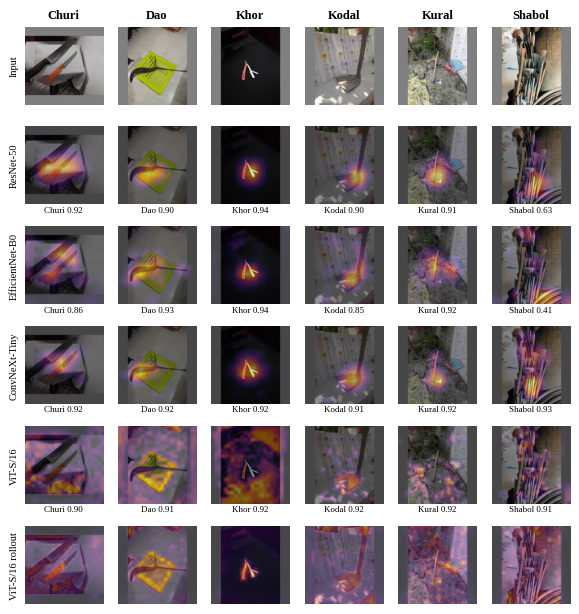

Done: /kaggle/working/gradcam_all_models.zip


In [5]:
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "pdf.fonttype": 42})
overlay = lambda img, cam: (0.55 * img / 255 + 0.45 * plt.get_cmap("inferno")(cam)[..., :3]).clip(0, 1)
heads = ["Input"] + [NAME[m] for m in MODELS] + (["ViT-S/16 rollout"] if ("rollout", pick[0]) in KEEP else [])
fig, axes = plt.subplots(len(heads), len(pick), figsize=(1.2 * len(pick), 1.25 * len(heads)), squeeze=False,
                         gridspec_kw=dict(wspace=0.03, hspace=0.28))
for j, i in enumerate(pick):
    tiles = [(IMGS[i] / 255, "")]
    for m in MODELS:
        c, lab, conf = KEEP[(m, i)]; tiles.append((overlay(IMGS[i], c), f"{lab} {conf:.2f}"))
    if ("rollout", i) in KEEP:
        tiles.append((overlay(IMGS[i], KEEP[("rollout", i)]), ""))
    for r_, (im, t) in enumerate(tiles):
        ax = axes[r_, j]; ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values(): s.set_visible(False)
        if t: ax.set_xlabel(t, fontsize=6.5, labelpad=1)
        if r_ == 0: ax.set_title(tst.label[i], fontsize=9, fontweight="bold")
        if j == 0: ax.set_ylabel(heads[r_], fontsize=7.5)
for ext in ("pdf", "png"):
    fig.savefig(OUT / f"gradcam_all_models.{ext}", dpi=300, bbox_inches="tight")
plt.show()
with zipfile.ZipFile(WORK / "gradcam_all_models.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f"{OUT.name}/{f.name}")
print("Done:", WORK / "gradcam_all_models.zip")